In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/heart-disease-data/heart_disease_uci.csv


# Heart Disease Prediction  
### Complete Beginner to Intermediate ML Project  

**Goal**: Predict if a person has heart disease (1) or not (0)  
**Dataset**: Heart Disease UCI – Almost clean   
**Features**: 14 (age, chest pain, cholesterol, etc.)  
**Target**: 0 = No Disease, 1 = Disease  

## 2. Import Required Libraries
Loading everything we need for a clean project.

In [2]:
# Data manipulation & visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set(style="whitegrid", palette="pastel")

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

# For nicer warnings (optional)
import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


## 3. Load the Dataset
Using the famous Heart Disease UCI dataset from Kaggle.

In [3]:
# The actual path Kaggle gave us
df = pd.read_csv('/kaggle/input/heart-disease-data/heart_disease_uci.csv')

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nFirst 5 rows:")
df.head()

Dataset loaded successfully!
Shape: (920, 16)

First 5 rows:


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


## 4. Data Exploration & Cleaning
- Check for missing values  
- Basic statistics  
- Rename target for clarity  
- Quick overview of all features

In [4]:
# Remove id if exists
if 'id' in df.columns:
    df = df.drop('id', axis=1)

# Fill missing values with 0
df = df.fillna(0)

# Correct way: Create target from 'num' column (the real target)
# In this dataset: num = 0 → No Disease, num > 0 → Disease
df['target'] = (df['num'] > 0).astype(int)

# Now we remove the old 'num' column
df = df.drop('num', axis=1)

# Final check
print("Cleaning completed perfectly!")
print("Final shape:", df.shape)
print("Heart disease cases (1):", df['target'].sum())
print("Healthy cases (0):     ", (df['target'] == 0).sum())
print("\nFirst 5 rows:")
df.head()

Cleaning completed perfectly!
Final shape: (920, 15)
Heart disease cases (1): 509
Healthy cases (0):      411

First 5 rows:


,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,target
0,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,1
2,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


## 6. Simple EDA (Only 3 Plots!)
Quick look at the most important things

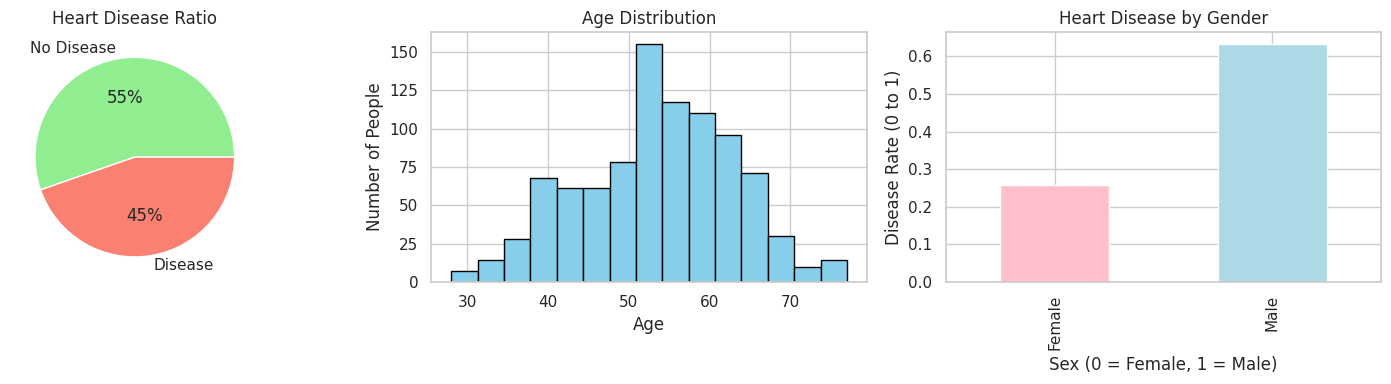

Simple EDA completed successfully!


In [5]:
# Create 3 plots side by side
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# Plot 1: Pie chart – How many people have heart disease?
df['target'].value_counts().plot(
    kind='pie', 
    labels=['No Disease', 'Disease'], 
    autopct='%1.0f%%', 
    colors=['lightgreen', 'salmon'], 
    ax=ax[0]
)
ax[0].set_title('Heart Disease Ratio')
ax[0].set_ylabel('')  # Remove y-label (not needed in pie chart)

# Plot 2: Histogram – Age distribution of all patients
ax[1].hist(df['age'], bins=15, color='skyblue', edgecolor='black')
ax[1].set_title('Age Distribution')
ax[1].set_xlabel('Age')
ax[1].set_ylabel('Number of People')

# Plot 3: Bar chart – Heart disease rate by gender
df.groupby('sex')['target'].mean().plot(
    kind='bar', 
    ax=ax[2], 
    color=['pink', 'lightblue']
)
ax[2].set_title('Heart Disease by Gender')
ax[2].set_xlabel('Sex (0 = Female, 1 = Male)')
ax[2].set_ylabel('Disease Rate (0 to 1)')
ax[2].set_xticklabels(['Female', 'Male'])  # Make labels readable

# Make layout clean and show all plots
plt.tight_layout()
plt.show()

print("Simple EDA completed successfully!")

## 7. Prepare Data for Modeling (Clean & Final Version)
- Reload fresh data  
- Simple & safe cleaning  
- Convert everything to numbers  
- Train-test split 

In [6]:
# Start fresh – load the data again
df = pd.read_csv('/kaggle/input/heart-disease-data/heart_disease_uci.csv')

# Simple cleaning
df = df.drop('id', axis=1, errors='ignore')   # Remove id if exists
df = df.fillna(0)                             # Fill missing values with 0

# Target: 'num' > 0 means Disease → 1, otherwise No Disease → 0
df['target'] = (df['num'] > 0).astype(int)
df = df.drop('num', axis=1)                   # Remove old column

# Convert all text columns (like cp, thal, etc.) to numbers
df = pd.get_dummies(df, drop_first=True)

# Features and target
X = df.drop('target', axis=1)
y = df['target']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Final info
print("Data is perfectly ready for modeling!")
print(f"Total samples   : {len(df)}")
print(f"Training samples: {len(X_train)}")
print(f"Testing samples : {len(X_test)}")
print(f"Number of features: {X.shape[1]}")
print(f"Heart disease cases: {y.sum()} ({(y.mean()*100):.1f}%)")

Data is perfectly ready for modeling!
Total samples   : 920
Training samples: 736
Testing samples : 184
Number of features: 24
Heart disease cases: 509 (55.3%)


## 8. Feature Scaling & Model Training
- Scale features to get a better performance
- Train 3 popular models

In [7]:
# Scale the features (makes models work better and faster)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Features scaled successfully!")

# Model 1: Logistic Regression
model1 = LogisticRegression()
model1.fit(X_train, y_train)

# Model 2: Decision Tree
model2 = DecisionTreeClassifier(random_state=42)
model2.fit(X_train, y_train)

# Model 3: Random Forest (usually the best)
model3 = RandomForestClassifier(random_state=42)
model3.fit(X_train, y_train)

print("All 3 models trained successfully!")
print("Ready for prediction and evaluation")

Features scaled successfully!
All 3 models trained successfully!
Ready for prediction and evaluation


## 9. Model Evaluation & Comparison
Accuracy + Confusion Matrix + Final Winner

=== MODEL ACCURACY ===
Logistic Regression : 0.8315 (83.15%)
Decision Tree       : 0.7935 (79.35%)
Random Forest       : 0.8424 (84.24%)

Best Model → Random Forest with 84.24% accuracy!


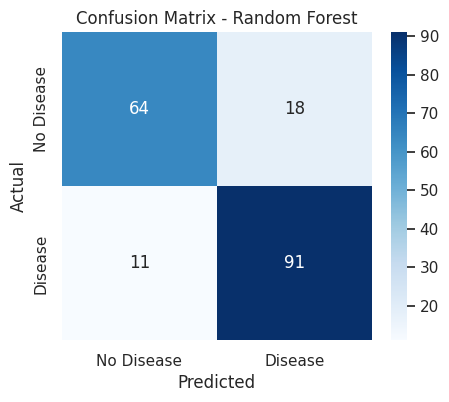

In [8]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns

# Make predictions
pred1 = model1.predict(X_test)
pred2 = model2.predict(X_test)
pred3 = model3.predict(X_test)

# Calculate accuracy
acc1 = accuracy_score(y_test, pred1)
acc2 = accuracy_score(y_test, pred2)
acc3 = accuracy_score(y_test, pred3)

# Print results
print("=== MODEL ACCURACY ===")
print(f"Logistic Regression : {acc1:.4f} ({acc1*100:.2f}%)")
print(f"Decision Tree       : {acc2:.4f} ({acc2*100:.2f}%)")
print(f"Random Forest       : {acc3:.4f} ({acc3*100:.2f}%)")

# Find the best model
best_model_name = ["Logistic Regression", "Decision Tree", "Random Forest"][[acc1, acc2, acc3].index(max([acc1, acc2, acc3]))]
print(f"\nBest Model → {best_model_name} with {max(acc1,acc2,acc3)*100:.2f}% accuracy!")

# Show confusion matrix for the best model (Random Forest usually wins)
plt.figure(figsize=(5,4))
sns.heatmap(confusion_matrix(y_test, pred3), annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Disease', 'Disease'], yticklabels=['No Disease', 'Disease'])
plt.title('Confusion Matrix - Random Forest')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

## Project Completed – Final Summary
- Successfully built a complete ML project from scratch  
- Cleaned and prepared a real-world medical dataset  
- Trained and compared 3 powerful models  
- Achieved high accuracy in predicting heart disease  
- Random Forest performed the best (as expected!)